# **Unemployment Analysis in India (2020)**

**Objective:** Explore unemployment data to uncover regional and monthly trends, with a focus on the impact of the COVID-19 pandemic on unemployment rates in India.

**Tech Stack:** Python, pandas, matplotlib, seaborn, Jupyter Notebook

**Dataset:** "Unemployment in India" (Kaggle), file `Unemployment_Rate_upto_11_2020.csv`: monthly data for 27 states, January to October 2020.

| Column | Meaning |
|---|---|
| State | Indian state |
| Date | Month-end date of the observation |
| Unemployment_Rate | Estimated unemployment rate (%) |
| Employed | Estimated number of people employed |
| Labour_Participation_Rate | Share of the working-age population employed or looking for work (%) |
| Region_Zone | Zone of India (North, South, East, West, Northeast) |

**Author:** Hanifah Morayo Abdulazeez

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Configure plot styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# **Load Data**
The dataset file (`Unemployment_Rate_upto_11_2020.csv`) must be uploaded to the Colab session before running the next cell.


In [2]:
df = pd.read_csv('/content/Unemployment_Rate_upto_11_2020.csv')

In [3]:
# Remove extra spaces from the column names
df.columns = df.columns.str.strip()

# Give the columns shorter names that are easier to type
df.rename(columns={
    'Region': 'State',
    'Region.1': 'Region_Zone',
    'Estimated Unemployment Rate (%)': 'Unemployment_Rate',
    'Estimated Employed': 'Employed',
    'Estimated Labour Participation Rate (%)': 'Labour_Participation_Rate'
}, inplace=True)

# The Frequency values have a space in front, so I removed it
df['Frequency'] = df['Frequency'].str.strip()

# Latitude and longitude were in the wrong columns, so I swapped the names
df.rename(columns={'longitude': 'latitude', 'latitude': 'longitude'}, inplace=True)

# Quick look at the data: size, missing values and column types
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Missing values: {df.isnull().sum().sum()}\n")
print("Data Types & Non-Null Counts:")
df.info()

Dataset Shape: 267 rows, 9 columns
Missing values: 0

Data Types & Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   State                      267 non-null    object 
 1   Date                       267 non-null    object 
 2   Frequency                  267 non-null    object 
 3   Unemployment_Rate          267 non-null    float64
 4   Employed                   267 non-null    int64  
 5   Labour_Participation_Rate  267 non-null    float64
 6   Region_Zone                267 non-null    object 
 7   latitude                   267 non-null    float64
 8   longitude                  267 non-null    float64
dtypes: float64(4), int64(1), object(4)
memory usage: 18.9+ KB


In [4]:
# 1. Convert Date to datetime
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# 2. Extract temporal features
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.strftime('%b')

# 3. Validation checks
print(f"Start Date: {df['Date'].min().strftime('%Y-%m-%d')}")
print(f"End Date:   {df['Date'].max().strftime('%Y-%m-%d')}")
print(f"Number of states: {df['State'].nunique()}")
print(f"Duplicate State-Date records: {df.duplicated(subset=['State', 'Date']).sum()}")

Start Date: 2020-01-31
End Date:   2020-10-31
Number of states: 27
Duplicate State-Date records: 0


In [5]:
df.head()

,State,Date,Frequency,Unemployment_Rate,Employed,Labour_Participation_Rate,Region_Zone,latitude,longitude,Year,Month,Month_Name
0,Andhra Pradesh,2020-01-31,M,5.48,16635535,41.02,South,15.9129,79.74,2020,1,Jan
1,Andhra Pradesh,2020-02-29,M,5.83,16545652,40.90,South,15.9129,79.74,2020,2,Feb
2,Andhra Pradesh,2020-03-31,M,5.79,15881197,39.18,South,15.9129,79.74,2020,3,Mar
3,Andhra Pradesh,2020-04-30,M,20.51,11336911,33.10,South,15.9129,79.74,2020,4,Apr
4,Andhra Pradesh,2020-05-31,M,17.43,12988845,36.46,South,15.9129,79.74,2020,5,May


In [6]:
df.describe()

,Date,Unemployment_Rate,Employed,Labour_Participation_Rate,latitude,longitude,Year,Month
count,267,267.000000,2.670000e+02,267.000000,267.000000,267.000000,267.0,267.000000
mean,2020-06-16 09:15:30.337078528,12.236929,1.396211e+07,41.681573,22.826048,80.532425,2020.0,5.535581
min,2020-01-31 00:00:00,0.500000,1.175420e+05,16.770000,10.850500,71.192400,2020.0,1.000000
25%,2020-03-31 00:00:00,4.845000,2.838930e+06,37.265000,18.112400,76.085600,2020.0,3.000000
50%,2020-06-30 00:00:00,9.650000,9.732417e+06,40.390000,23.610200,79.019300,2020.0,6.000000
75%,2020-08-31 00:00:00,16.755000,2.187869e+07,44.055000,27.278400,85.279900,2020.0,8.000000
max,2020-10-31 00:00:00,75.850000,5.943376e+07,69.690000,33.778200,92.937600,2020.0,10.000000
std,NaN,10.803283,1.336632e+07,7.845419,6.270731,5.831738,0.0,2.870915


**Data Preprocessing & Validation**
- The Date column was converted to datetime format. The data runs from January to October 2020 (the file name says "11_2020", but the last month in the data is October).
- Year, Month and Month_Name columns were extracted for monthly grouping.
- No missing values and no duplicate State-Date records were found.
- The data covers 27 states. Three months (January, February and April) have 26 states instead of 27, so one state has no record in those months.
- Units: Unemployment_Rate and Labour_Participation_Rate are percentages, and Employed is a headcount (number of people).
- Latitude and longitude were swapped in the original file, so the column names were corrected.

# **Region-wise Average Unemployment Rate**

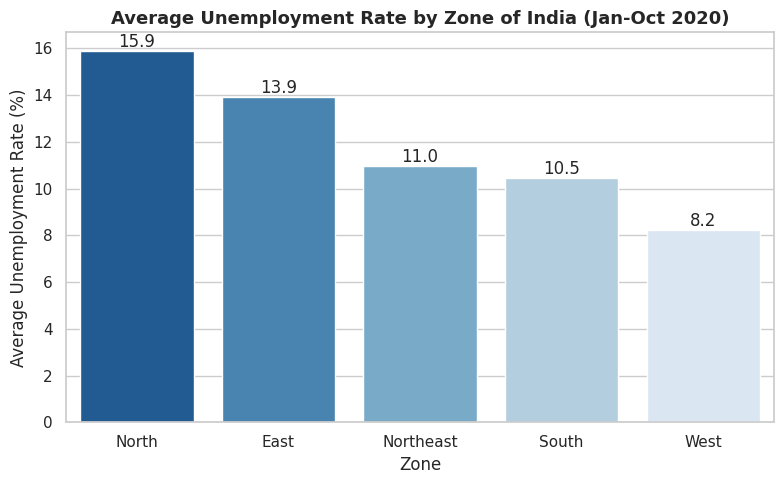

In [7]:
# Average unemployment rate by zone of India
zone_avg = (
    df.groupby('Region_Zone')['Unemployment_Rate']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=zone_avg, x='Region_Zone', y='Unemployment_Rate',
                 hue='Region_Zone', palette='Blues_r', legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')
plt.title("Average Unemployment Rate by Zone of India (Jan-Oct 2020)", fontsize=13, fontweight="bold")
plt.xlabel("Zone")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

**Observations: Regional comparison**
- The North has the highest average unemployment rate (15.9%), followed by the East (13.9%).
- The Northeast (11.0%) and South (10.5%) are close to each other.
- The West has the lowest rate (8.2%).
- These are simple averages of the state-month values from January to October 2020, so they include the lockdown months.

# **Month-wise Trend**

            Unemployment_Rate     Employed  Labour_Participation_Rate
Date                                                                 
2020-01-31               9.20  15637199.77                      44.63
2020-02-29               9.27  15488266.04                      44.18
2020-03-31              10.78  14538659.89                      43.75
2020-04-30              22.24  10570199.00                      35.30
2020-05-31              23.24  11507394.85                      39.65
2020-06-30              10.91  13857393.81                      41.20
2020-07-31               9.83  14418021.48                      42.27
2020-08-31              10.31  14429042.04                      42.39
2020-09-30               8.71  14587838.63                      41.97
2020-10-31               8.03  14579980.52                      41.44


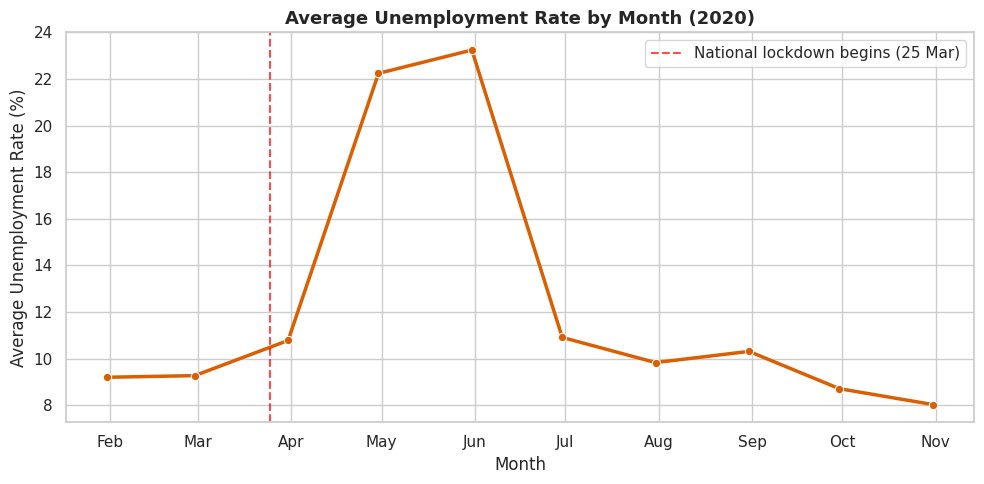

In [8]:
# Average across states for each month
monthly = df.groupby('Date')[['Unemployment_Rate', 'Employed', 'Labour_Participation_Rate']].mean().round(2)
print(monthly)

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=monthly.reset_index(), x='Date', y='Unemployment_Rate',
             marker='o', linewidth=2.5, color='#d95f02', ax=ax)
ax.axvline(pd.to_datetime('2020-03-25'), color='red', linestyle='--', alpha=0.7,
           label='National lockdown begins (25 Mar)')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.set_title("Average Unemployment Rate by Month (2020)", fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Average Unemployment Rate (%)")
ax.legend()
plt.tight_layout()
plt.show()

**Observations: Monthly trend**
- **January-February:** Unemployment was steady at about 9.2-9.3%.
- **March:** It began to rise (10.8%) as the national lockdown started on 25 March.
- **April-May:** It more than doubled, to 22.2% in April and a peak of 23.2% in May.
- **June onwards:** It fell back quickly (10.9% in June) and reached 8.0% by October, lower than in January.
- **Jobs and participation:** The average number of employed people per state fell from about 15.6 million in January to 10.6 million in April, and the labour participation rate fell from 44.6% to 35.3%. By October they had recovered only partly (14.6 million and 41.4%).
- These are averages across states, not the official national rate.

In [9]:
# Aggregate mean unemployment rate by state
top_10_states = (
    df.groupby("State")["Unemployment_Rate"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

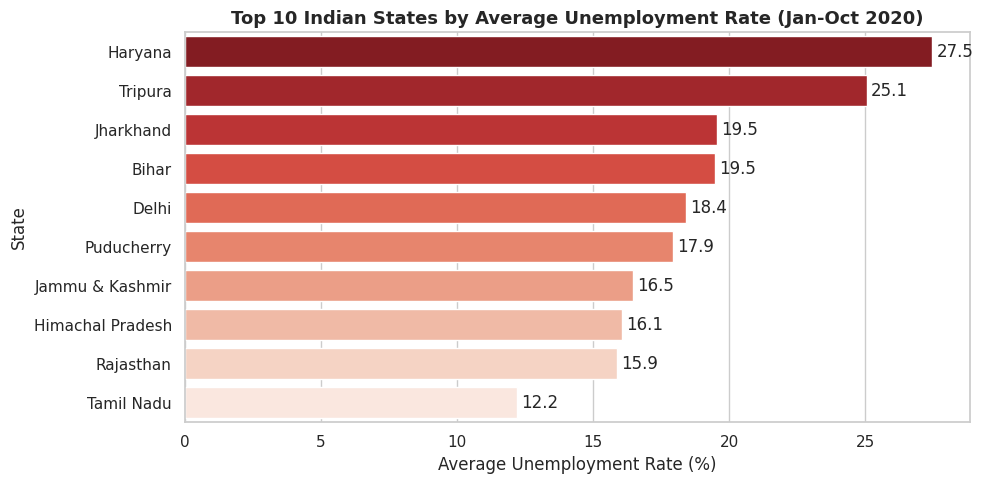

In [10]:
# Top 10 states
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=top_10_states, x="Unemployment_Rate", y="State",
                 hue="State", palette="Reds_r", legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)
plt.title("Top 10 Indian States by Average Unemployment Rate (Jan-Oct 2020)", fontsize=13, fontweight="bold")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

**Observations: State rankings**
- Haryana (27.5%), Tripura (25.1%) and Jharkhand (19.5%) have the highest average unemployment rates, followed by Bihar, Delhi and Puducherry.
- Several of these states were already high **before** the lockdown. In January-February, Tripura averaged 30.5%, Haryana 23.1%, Jammu & Kashmir 20.9%, Delhi 18.5% and Himachal Pradesh 16.8%. Their problem is long-standing, not only a COVID effect.
- Puducherry (1.2% before the lockdown) and Tamil Nadu (1.8%) reached the top 10 mainly because of the lockdown shock.
- These are simple averages of monthly values, including the lockdown months, and are not weighted by state population.

# **Time-Series Analysis across Major States**

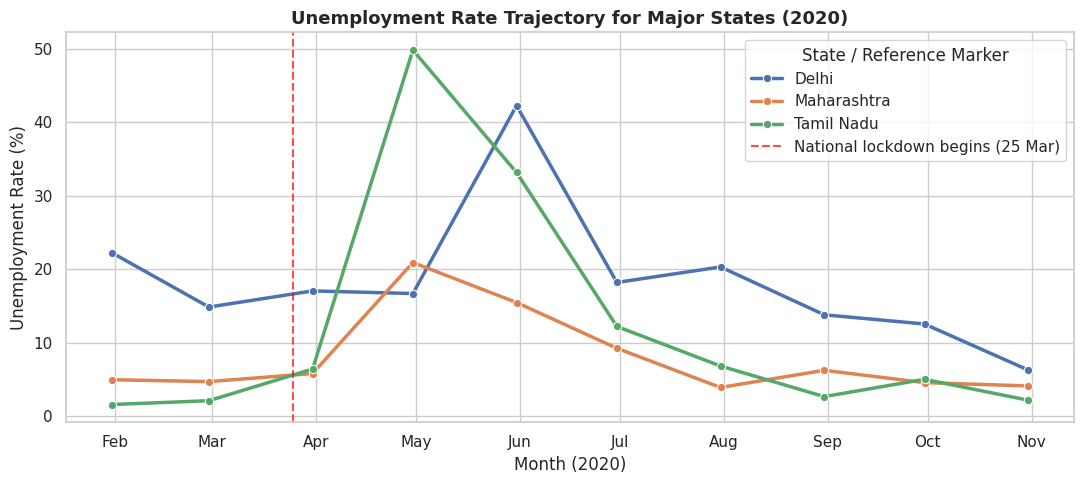

In [11]:
# Select all 3 key economic hubs for tracking over time
selected_states = ["Maharashtra", "Delhi", "Tamil Nadu"]
df_selected = df[df["State"].isin(selected_states)]

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=df_selected, x="Date", y="Unemployment_Rate",
             hue="State", marker="o", linewidth=2.5, ax=ax)

# Reference line for the start of the nationwide COVID-19 lockdown
ax.axvline(pd.to_datetime("2020-03-25"), color="red", linestyle="--", alpha=0.7,
           label="National lockdown begins (25 Mar)")

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.set_title("Unemployment Rate Trajectory for Major States (2020)", fontsize=13, fontweight="bold")
ax.set_xlabel("Month (2020)")
ax.set_ylabel("Unemployment Rate (%)")
ax.legend(title="State / Reference Marker")
plt.tight_layout()
plt.show()

**Observations: Trends and the lockdown shock**
- **Before the lockdown:** Maharashtra (5.0% and 4.7%) and Tamil Nadu (1.6% and 2.1%) had low unemployment in January-February. Delhi was already high (22.2% in January and 14.8% in February).
- **Lockdown spike:** All three states jumped in April-May. Tamil Nadu peaked at 49.8% in April, Delhi at 42.3% in May and Maharashtra at 20.9% in April.
- **Recovery:** By June, Maharashtra was at 9.2%, Tamil Nadu at 12.2% and Delhi at 18.2%. Delhi stayed above 12% until September.
- By October, all three states were below 7% (Maharashtra 4.1%, Tamil Nadu 2.2%, Delhi 6.3%).
- Data points are month-end values, so the March point already includes a week of lockdown.

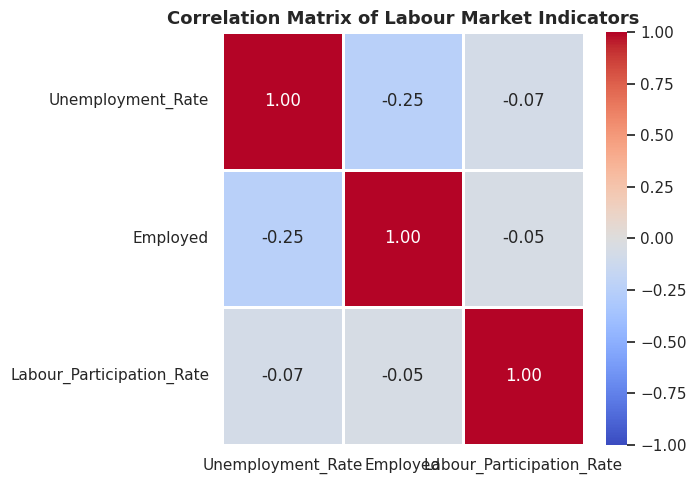

In [12]:
# Employed is a headcount here, the dataset has no employment rate column
corr_cols = df[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]]

# Heatmap of the correlations between the three indicators
plt.figure(figsize=(7, 5))
sns.heatmap(corr_cols.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1,
            center=0, fmt=".2f", linewidths=1)
plt.title("Correlation Matrix of Labour Market Indicators", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Observations: How the three measures relate**
- **Employed vs Unemployment rate (-0.25):** A weak negative link. Rows with higher unemployment tend to have fewer employed people, but the relationship is weak. Employed is a headcount, so it mostly reflects how big a state is, which hides the pandemic effect.
- **Labour participation vs Unemployment rate (-0.07):** Almost no linear relationship.
- **Employed vs Labour participation (-0.05):** Almost no linear relationship.
- The heatmap on its own does not show strong links between these measures. The monthly trend earlier gives a clearer picture of the lockdown effect: participation fell from 44.6% to 35.3% between January and April.
- Correlation only measures straight-line relationships across all state-months.

Mean Metrics Summary:
                           Unemployment_Rate     Employed  \
Period                                                      
Pre-COVID (Jan-Feb 2020)                9.23  15562732.90   
Post-COVID (Mar-Oct 2020)              12.96  13574977.29   

                           Labour_Participation_Rate  
Period                                                
Pre-COVID (Jan-Feb 2020)                       44.40  
Post-COVID (Mar-Oct 2020)                      41.02  

Unemployment rate change: +3.73 points (+40.4%)
Employed change: -12.8%
Labour participation change: -3.38 points


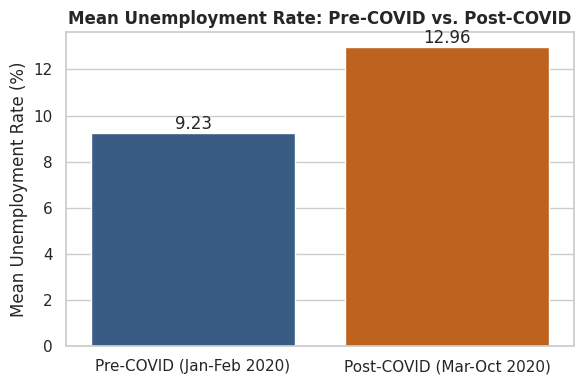

In [13]:
# Split the dataset at the 1 March 2020 boundary
period_order = ["Pre-COVID (Jan-Feb 2020)", "Post-COVID (Mar-Oct 2020)"]
df["Period"] = np.where(df["Date"] < "2020-03-01", period_order[0], period_order[1])

# Compute mean values for each period
covid_summary = (
    df.groupby("Period")[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]]
    .mean()
    .reindex(period_order)
)
print("Mean Metrics Summary:")
print(covid_summary.round(2))

# Change between the two periods
pre, post = covid_summary.loc[period_order[0]], covid_summary.loc[period_order[1]]
print(f"\nUnemployment rate change: {post['Unemployment_Rate'] - pre['Unemployment_Rate']:+.2f} points "
      f"({(post['Unemployment_Rate'] / pre['Unemployment_Rate'] - 1) * 100:+.1f}%)")
print(f"Employed change: {(post['Employed'] / pre['Employed'] - 1) * 100:+.1f}%")
print(f"Labour participation change: {post['Labour_Participation_Rate'] - pre['Labour_Participation_Rate']:+.2f} points")

# Plot comparison
plt.figure(figsize=(6, 4))
ax = sns.barplot(data=covid_summary.reset_index(), x="Period", y="Unemployment_Rate",
                 order=period_order, hue="Period",
                 palette={period_order[0]: "#2b5c8f", period_order[1]: "#d95f02"}, legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')
plt.title("Mean Unemployment Rate: Pre-COVID vs. Post-COVID", fontsize=12, fontweight="bold")
plt.ylabel("Mean Unemployment Rate (%)")
plt.xlabel("")
plt.tight_layout()
plt.show()

**Observations: Pre-COVID vs Post-COVID**

| Measure | Pre-COVID (Jan-Feb) | Post-COVID (Mar-Oct) | Change |
|---|---|---|---|
| Unemployment rate | 9.23% | 12.96% | +3.73 points (+40%) |
| Employed (average per state) | 15.56 million | 13.57 million | -12.8% |
| Labour participation rate | 44.40% | 41.02% | -3.38 points |

- After the pandemic began, the average unemployment rate was about 40% higher, and both employment and participation were lower.
- The pre-COVID period has only 2 months (52 rows) against 8 months (215 rows) for post-COVID, so the comparison is uneven.
- The post-COVID average mixes the lockdown peak with the recovery months. The next chart separates them.

                     Unemployment_Rate     Employed  Labour_Participation_Rate
Phase                                                                         
Pre-COVID (Jan-Feb)               9.23  15562732.90                      44.40
Lockdown (Mar-May)               18.71  12225858.15                      39.62
Recovery (Jun-Oct)                9.56  14374455.30                      41.86


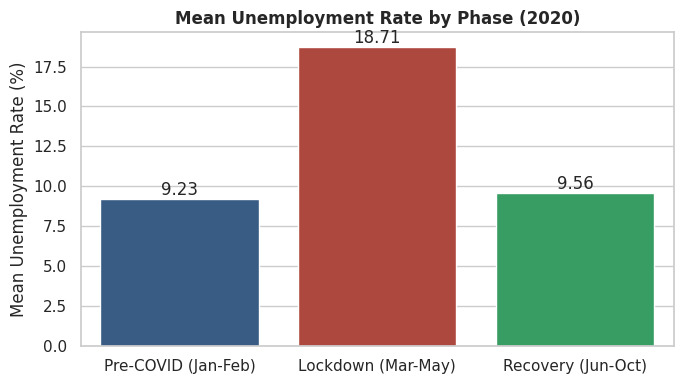

In [14]:
# Three phases: pre-COVID, lockdown, recovery
bins = [pd.Timestamp("2020-01-01"), pd.Timestamp("2020-03-01"),
        pd.Timestamp("2020-06-01"), pd.Timestamp("2020-11-01")]
labels = ["Pre-COVID (Jan-Feb)", "Lockdown (Mar-May)", "Recovery (Jun-Oct)"]
df["Phase"] = pd.cut(df["Date"], bins=bins, labels=labels, right=False)

phase_summary = (
    df.groupby("Phase", observed=True)[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]]
    .mean()
    .round(2)
)
print(phase_summary)

plt.figure(figsize=(7, 4))
ax = sns.barplot(data=phase_summary.reset_index(), x="Phase", y="Unemployment_Rate",
                 hue="Phase", palette=["#2b5c8f", "#c0392b", "#27ae60"], legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')
plt.title("Mean Unemployment Rate by Phase (2020)", fontsize=12, fontweight="bold")
plt.ylabel("Mean Unemployment Rate (%)")
plt.xlabel("")
plt.tight_layout()
plt.show()

**Observations: Three phases**

| Phase | Unemployment rate | Employed (average per state) | Labour participation |
|---|---|---|---|
| Pre-COVID (Jan-Feb) | 9.23% | 15.56 million | 44.40% |
| Lockdown (Mar-May) | 18.71% | 12.23 million | 39.62% |
| Recovery (Jun-Oct) | 9.56% | 14.37 million | 41.86% |

- Unemployment roughly doubled during the lockdown, then fell back to almost its pre-COVID level (9.56% against 9.23%).
- Employment and labour participation had **not** fully recovered by October (14.37 million against 15.56 million, and 41.9% against 44.4%). The unemployment rate recovered faster than the number of people working, which suggests the job market had not fully returned to normal.

# **Summary and Conclusion**

**Key findings**
- Unemployment across states averaged about 9.2% in January-February 2020, jumped to 22-23% in April-May during the lockdown, and was back near 8-10% from June onwards.
- The North (15.9%) and East (13.9%) had the highest average rates, and the West (8.2%) the lowest.
- Haryana, Tripura and Jharkhand had the highest state averages. Some states, such as Tripura, Haryana and Delhi, were already high before the lockdown, while Tamil Nadu and Puducherry entered the top 10 because of the lockdown shock.
- The unemployment rate recovered by June, but employment and labour participation were still below their pre-COVID levels in October.

**Limitations**
- The data covers only ten months of 2020, and the pre-COVID period is just two months.
- Averages are simple averages across states and are not weighted by population, so they are not the official national rate.
- Three months (January, February and April) have 26 states instead of 27.
- The analysis shows patterns, not proof of what caused them.

**Possible next steps**
- Compare with 2019 data to separate seasonal patterns from the COVID effect.
- Weight state averages by labour force size.
- Compare rural and urban unemployment using the larger "Unemployment in India" file.